# PS5: Facial emotion recognition with a CNN (FER-2013)
Dataset layout: FER-2013/train/<emotion>/*.jpg and FER-2013/test/<emotion>/*.jpg (48x48 grayscale).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = "../datasets/FER-2013"
EPOCHS = 25
IMG = (48, 48)

In [2]:
train_ds = keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/train", color_mode="grayscale", image_size=IMG, batch_size=64,
    validation_split=0.1, subset="training", seed=42)
val_ds = keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/train", color_mode="grayscale", image_size=IMG, batch_size=64,
    validation_split=0.1, subset="validation", seed=42)
test_ds = keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/test", color_mode="grayscale", image_size=IMG, batch_size=64, shuffle=False)
class_names = train_ds.class_names
print(class_names)

Found 28709 files belonging to 7 classes.


Using 25839 files for training.


Found 28709 files belonging to 7 classes.


Using 2870 files for validation.


Found 7178 files belonging to 7 classes.


['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


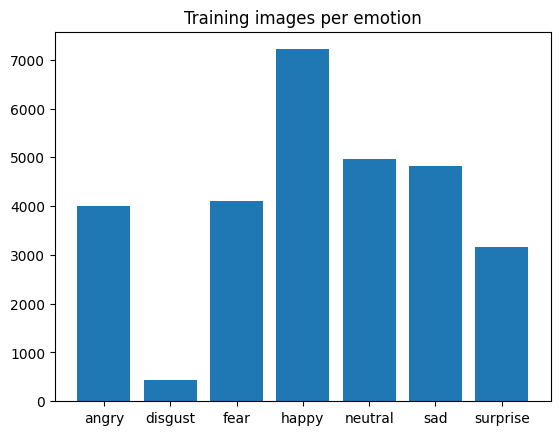

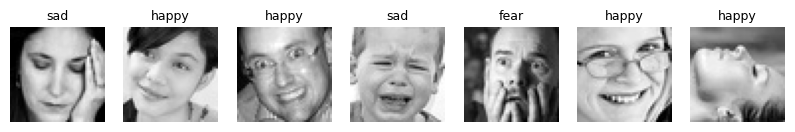

In [3]:
counts = [len(tf.io.gfile.listdir(f"{DATA_DIR}/train/{c}")) for c in class_names]
plt.bar(class_names, counts)
plt.title("Training images per emotion")
plt.show()

plt.figure(figsize=(10, 3))
for images, labels in train_ds.take(1):
    for i in range(7):
        plt.subplot(1, 7, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis("off")
plt.show()

train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)

In [4]:
model = keras.Sequential([
    layers.Input(IMG + (1,)),
    layers.Rescaling(1 / 255.0),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,275,271 (4.86 MB)

 Trainable params: 1,274,823 (4.86 MB)

 Non-trainable params: 448 (1.75 KB)

In [5]:
history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)], verbose=2)

Epoch 1/25


404/404 - 36s - 89ms/step - accuracy: 0.2557 - loss: 1.8935 - val_accuracy: 0.1610 - val_loss: 3.2152


Epoch 2/25


404/404 - 28s - 69ms/step - accuracy: 0.3103 - loss: 1.6929 - val_accuracy: 0.3303 - val_loss: 1.6646


Epoch 3/25


404/404 - 27s - 67ms/step - accuracy: 0.3415 - loss: 1.6359 - val_accuracy: 0.3537 - val_loss: 1.6159


... (40 outputs left out)

Epoch 24/25


404/404 - 27s - 68ms/step - accuracy: 0.5041 - loss: 1.2960 - val_accuracy: 0.5519 - val_loss: 1.1821


Epoch 25/25


404/404 - 27s - 68ms/step - accuracy: 0.5129 - loss: 1.2927 - val_accuracy: 0.5324 - val_loss: 1.2186


Test accuracy: 0.5490   Test loss: 1.1902


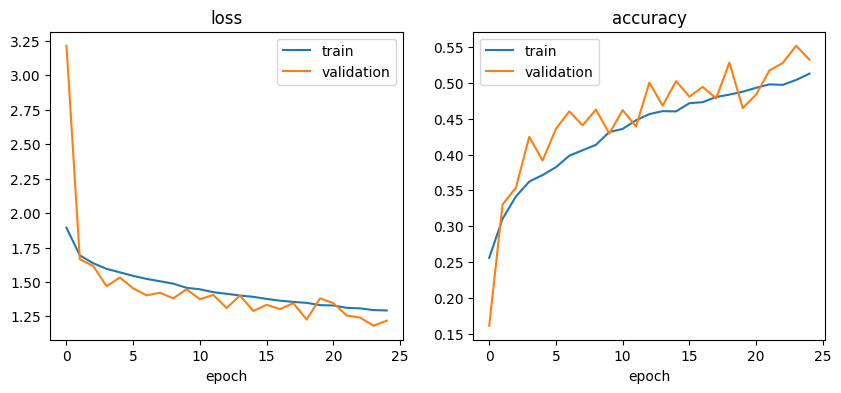

In [6]:
loss, acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {acc:.4f}   Test loss: {loss:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()

C:\23410023\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\23410023\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\23410023\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

       angry     0.5125    0.3006    0.3789       958
     disgust     0.0000    0.0000    0.0000       111
        fear     0.3674    0.2246    0.2788      1024
       happy     0.7983    0.8033    0.8008      1774
     neutral     0.4972    0.5831    0.5368      1233
         sad     0.3667    0.5702    0.4463      1247
    surprise     0.6927    0.6835    0.6881       831

    accuracy                         0.5490      7178
   macro avg     0.4621    0.4522    0.4471      7178
weighted avg     0.5474    0.5490    0.5377      7178



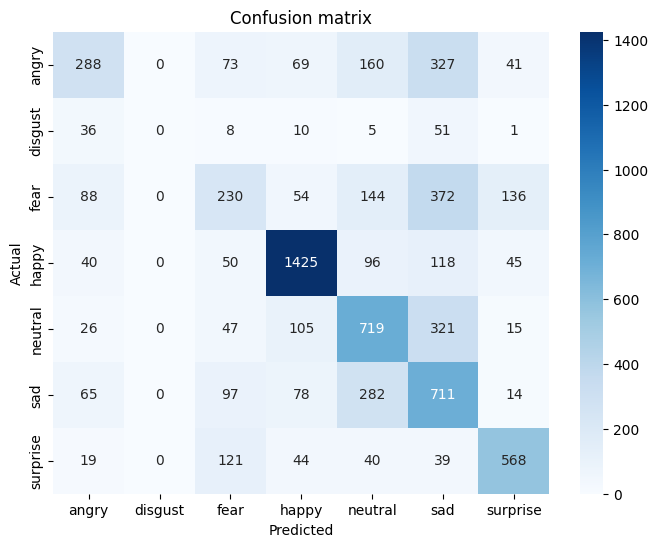

In [7]:
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

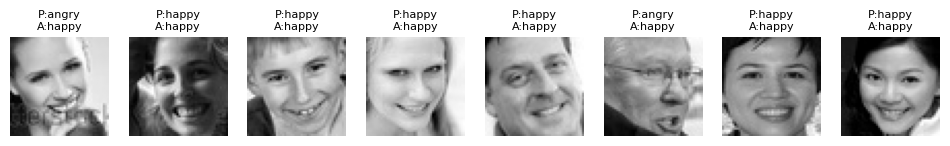

In [8]:
images, labels = next(iter(test_ds.shuffle(100)))
preds = model.predict(images, verbose=0).argmax(axis=1)
plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(images[i].numpy().squeeze(), cmap="gray")
    plt.title(f"P:{class_names[preds[i]]}\nA:{class_names[labels[i]]}", fontsize=8)
    plt.axis("off")
plt.show()